# 06 — LightGBM
### Telco Customer Churn Prediction

LightGBM is a second widely used gradient-boosting library. Together with notebooks 04 and 05, it shows whether any boosting implementation offers a meaningful gain on this dataset.

**Shared protocol** (identical in notebooks 01–06):
- Same training set (3,944 customers) and same 5 stratified folds (`random_state = 34`).
- Same preprocessing (`FINAL_PREP_CONFIG` from notebook 00): binary add-ons, one-hot `InternetService` and `Contract`, binary `Dependents`/`PaperlessBilling`, standardised `log(1 + tenure)` and `MonthlyCharges`.
- Same tuning procedure: **nested cross-validation** (inner 5-fold grid search, outer 5-fold evaluation), scored by PR-AUC.
- Unweighted classes; class imbalance is handled at the decision threshold (notebook 08) and examined in notebook 07.
- The test set is **not used**. The nested out-of-fold predictions saved at the end are used for comparison and threshold selection in notebook 08.

## 1. How the Algorithm Works

LightGBM is gradient boosting with histogram-based splits that grows trees **leaf-wise**: at each step it splits the leaf with the largest loss reduction, anywhere in the tree, so trees can be deep and unbalanced. `num_leaves` controls tree complexity.

**Differences from the other boosting libraries:**
- XGBoost grows trees level by level to a fixed depth.
- HistGradientBoosting also grows leaf-wise with a leaf limit and is scikit-learn's re-implementation of the LightGBM approach.
- LightGBM adds its own regularisation and sampling options, plus engineering optimisations aimed at very large datasets.

## 2. Relevance, Assumptions and Limitations

- **Relevance:** completes the boosting comparison.
- **Expectation:** on 3,944 rows its speed advantages are irrelevant, and results should be close to HistGradientBoosting's.
- **Limitations:**
  - leaf-wise growth can overfit small datasets unless `min_child_samples` and `num_leaves` are constrained;
  - low interpretability;
  - an extra dependency.

## 3. Setup

In [1]:
import sys
from pathlib import Path

# Make the project's shared src/ package importable, wherever Jupyter was started
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_preprocessing.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve
from lightgbm import LGBMClassifier
from src.data_preprocessing import FINAL_PREP_CONFIG, RANDOM_STATE, build_pipeline, load_raw_data, split_train_test
from src.evaluation import (cv_scores, final_search, fold_metrics, mean_std_table, nested_summary_row, run_nested_cv,
                            save_results, summarise_cv)
from src.visualization import plot_confusion, plot_permutation_importance, plot_reliability, save_figure, set_style

set_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

df = load_raw_data()                                       # validated raw data (read-only)
X_train, X_test, y_train, y_test = split_train_test(df)   # the project's single stratified 80/20 split
del X_test, y_test                                        # the test set is not used in this notebook
print(f"Training set: {X_train.shape[0]:,} customers, {int(y_train.sum()):,} churners ({y_train.mean():.2%})")
print("Preprocessing configuration (from notebook 00):", FINAL_PREP_CONFIG)

Training set: 3,944 customers, 1,053 churners (26.70%)
Preprocessing configuration (from notebook 00): {'contract': 'onehot', 'addons': 'binary', 'tenure': 'log'}


In [2]:
MODEL_NAME = "LightGBM"
SLUG = "06_lightgbm"
INTERPRETABILITY_RANK = 6  # 1 = most interpretable

## 4. Preprocessing Pipeline

The shared pipeline is used unchanged; LightGBM receives the same numeric matrix as the other models.

In [3]:
ESTIMATOR = LGBMClassifier(n_estimators=200, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1, verbose=-1)


pipeline = build_pipeline(ESTIMATOR, **FINAL_PREP_CONFIG)
print("Pipeline steps:", [name for name, _ in pipeline.steps])
print("Transformers:", [(name, cols) for name, _, cols in pipeline.named_steps["preprocess"].transformers])
print("Model:", ESTIMATOR)

Pipeline steps: ['preprocess', 'model']
Transformers: [('binary', ['Dependents', 'PaperlessBilling']), ('addons', ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']), ('internet', ['InternetService']), ('contract', ['Contract']), ('tenure_log', ['tenure']), ('numeric', ['MonthlyCharges'])]
Model: LGBMClassifier(colsample_bytree=0.8, n_estimators=200, n_jobs=1,
               random_state=34, subsample=0.8, subsample_freq=1, verbose=-1)


## 5. Baseline Configuration

The baseline uses LightGBM's defaults (learning rate 0.1, 100 trees, 31 leaves, `min_child_samples` 20).

In [4]:
BASELINE_ESTIMATOR = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1)


baseline_raw = cv_scores(build_pipeline(BASELINE_ESTIMATOR, **FINAL_PREP_CONFIG), X_train, y_train)
baseline = summarise_cv(baseline_raw)
display(mean_std_table(pd.DataFrame([baseline], index=["Baseline (5-fold CV, threshold 0.5)"])))
gap = {m: baseline[f"{m} train"] - baseline[f"{m} mean"] for m in ["F1", "ROC-AUC", "PR-AUC"]}
print("Train - validation gap:", {k: round(v, 3) for k, v in gap.items()})

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
"Baseline (5-fold CV, threshold 0.5)",0.781 ± 0.018,0.605 ± 0.044,0.525 ± 0.012,0.562 ± 0.023,0.826 ± 0.016,0.625 ± 0.025


Train - validation gap: {'F1': np.float64(0.224), 'ROC-AUC': np.float64(0.134), 'PR-AUC': np.float64(0.256)}


**Interpretation.**
- LightGBM's defaults (31 leaves, learning rate 0.1) give validation PR-AUC **0.625** and ROC-AUC 0.826.
- Training-fold PR-AUC is 0.256 higher: leaf-wise trees with 31 leaves overfit this dataset, the same pattern as HistGradientBoosting's defaults.

## 6. Hyperparameter Tuning Methodology


Hyperparameters are tuned with **nested cross-validation**:
- the 5 outer folds hold out 20% of the training set in turn;
- on the other 80%, a full grid search with its own inner 5-fold CV chooses the configuration;
- the chosen configuration, refitted on that 80%, predicts the held-out outer fold.

The outer-fold labels never influence tuning, so the resulting out-of-fold (OOF) probabilities are honest estimates of how the *whole hyperparameter-tuning procedure* performs on unseen customers. (The preprocessing configuration was fixed beforehand in notebook 00 using the same training folds; notebook 08, Section 6 shows that re-selecting it inside the nested loop changes the estimate only marginally.) A simpler "tune on everything, then cross-validate" design would reuse the same labels for selection and evaluation, which makes the estimates optimistic.

The search space has the same size as HistGradientBoosting's (36 configurations).

| Hyperparameter | Values | Role |
|---|---|---|
| `n_estimators` | 200 (fixed) | Number of boosting rounds |
| `subsample` (every iteration), `colsample_bytree` | 0.8 (fixed) | Row/column subsampling |
| `learning_rate` | 0.01, 0.03, 0.1 | Shrinkage of each tree (range extended after a first run selected the boundary value) |
| `num_leaves` | 4, 7, 15 | Complexity of each (leaf-wise) tree (range extended after a first run selected the boundary value) |
| `min_child_samples` | 20, 50 | Minimum customers per leaf |
| `reg_lambda` | 0, 1 | L2 penalty on leaf values |

In [5]:
PARAM_GRID = {"model__learning_rate": [0.01, 0.03, 0.1], "model__num_leaves": [4, 7, 15], "model__min_child_samples": [20, 50], "model__reg_lambda": [0.0, 1.0]}


n_configurations = int(np.prod([len(v) for v in PARAM_GRID.values()]))
print(f"{n_configurations} configurations x 5 inner folds x 5 outer folds = {n_configurations * 25} fits "
      f"(+ {5} refits) in the nested CV")

36 configurations x 5 inner folds x 5 outer folds = 900 fits (+ 5 refits) in the nested CV


## 7. Nested Cross-Validation Results

In [6]:
nested = run_nested_cv(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG, compute_importance=True)
print(f"Nested CV wall time: {nested['seconds']:.1f} s\n")
display(nested["folds"].round(4))
print("Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):")
display(pd.DataFrame([nested_summary_row(nested)], index=[MODEL_NAME]))
print("Hyperparameters chosen by the inner search in each outer fold:")
for fold, params in enumerate(nested["params"], start=1):
    print(f"  fold {fold}: {params}")

Nested CV wall time: 10.9 s



,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,log_loss
fold,,,,,,,,
1,0.7921,0.6407,0.5071,0.5661,0.8468,0.6536,0.1382,0.4259
2,0.8074,0.6810,0.5261,0.5936,0.8625,0.7010,0.1291,0.3990
3,0.7921,0.6284,0.5450,0.5838,0.8256,0.6574,0.1422,0.4405
4,0.7934,0.6497,0.4857,0.5559,0.8421,0.6521,0.1363,0.4207
5,0.7931,0.6767,0.4286,0.5248,0.8552,0.6603,0.1357,0.4197


Mean ± std over the 5 outer folds (accuracy, precision, recall and F1 at the reference threshold 0.5):


,PR-AUC,ROC-AUC,Brier score,Accuracy,Precision,Recall,F1
LightGBM,0.665 ± 0.018,0.846 ± 0.013,0.136 ± 0.004,0.796 ± 0.006,0.655 ± 0.020,0.498 ± 0.040,0.565 ± 0.024


Hyperparameters chosen by the inner search in each outer fold:
  fold 1: {'learning_rate': 0.01, 'min_child_samples': 50, 'num_leaves': 15, 'reg_lambda': 1.0}
  fold 2: {'learning_rate': 0.03, 'min_child_samples': 50, 'num_leaves': 7, 'reg_lambda': 1.0}
  fold 3: {'learning_rate': 0.03, 'min_child_samples': 20, 'num_leaves': 4, 'reg_lambda': 1.0}
  fold 4: {'learning_rate': 0.03, 'min_child_samples': 20, 'num_leaves': 4, 'reg_lambda': 1.0}
  fold 5: {'learning_rate': 0.01, 'min_child_samples': 50, 'num_leaves': 15, 'reg_lambda': 1.0}


**Interpretation.**
- Nested **PR-AUC 0.665 ± 0.018** and **ROC-AUC 0.846 ± 0.013**: equal to Logistic Regression and XGBoost within 0.002.
- **Boundary check:** after the grid was extended (learning rate 0.01, 4 leaves), the chosen settings vary across folds (4, 7 or 15 leaves; learning rate 0.01 or 0.03). The optimum is not stuck at an edge.
- The non-nested search score is almost identical to the nested estimate (optimism 0.0005).

## 8. Final Hyperparameters

The same grid search is run once on the full training set. Its refitted pipeline is this algorithm's final candidate, which notebook 09 evaluates if it is selected. Comparing the best search score with the nested estimate shows the optimism of a non-nested search.

In [7]:
search = final_search(ESTIMATOR, PARAM_GRID, X_train, y_train, FINAL_PREP_CONFIG)
final_params = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
final_summary = pd.Series({
    "best hyperparameters": final_params,
    "search CV PR-AUC (best of grid)": round(search.best_score_, 4),
    "nested CV PR-AUC": round(nested["folds"]["pr_auc"].mean(), 4),
    "optimism of the search score": round(search.best_score_ - nested["folds"]["pr_auc"].mean(), 4),
    "train-fold PR-AUC of best configuration": round(search.cv_results_["mean_train_score"][search.best_index_], 4),
})
display(final_summary.to_frame("value"))

,value
best hyperparameters,"{'learning_rate': 0.03, 'min_child_samples': 50, 'num_leaves': 4, 'reg_lambda': 1.0}"
search CV PR-AUC (best of grid),0.6654
nested CV PR-AUC,0.6649
optimism of the search score,0.0005
train-fold PR-AUC of best configuration,0.6866


## 9. Diagnostics (Nested Out-of-Fold Predictions)

The confusion matrix uses the reference threshold of 0.5 only; the operating threshold is chosen in notebook 08. The reliability diagram checks whether predicted probabilities match observed churn rates (**calibration**), and the precision-recall curve shows the ranking quality across all thresholds (**discrimination**).

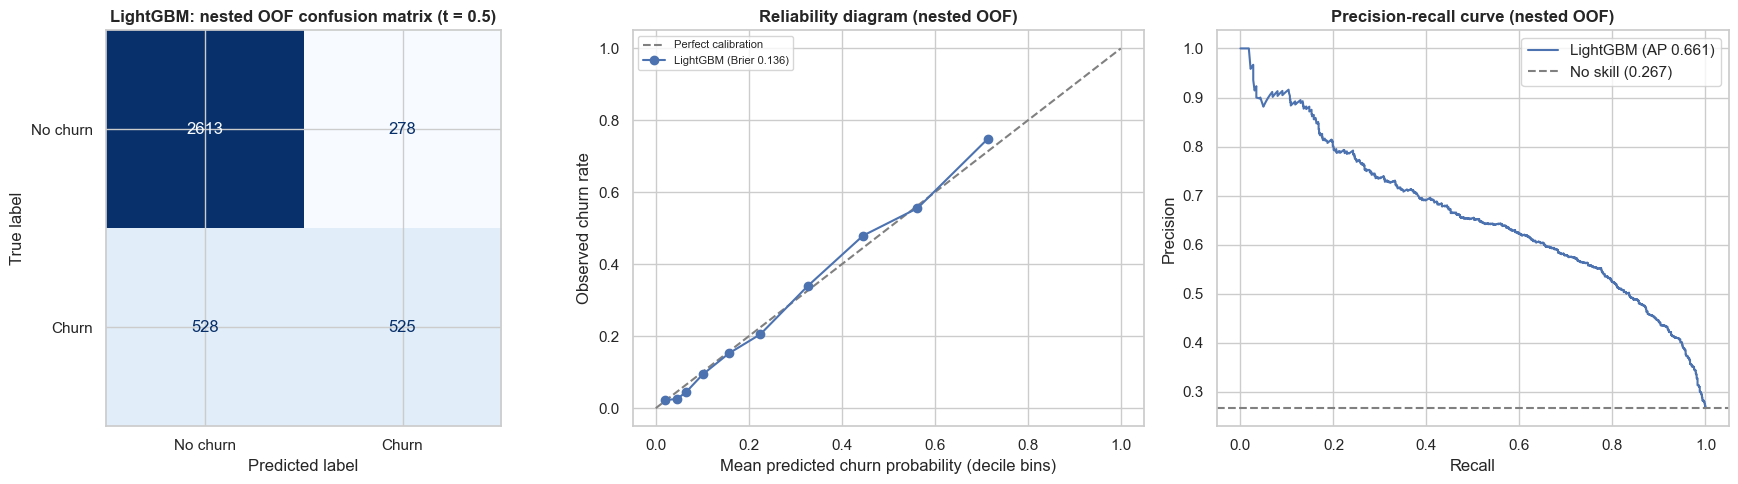

In [8]:
oof = nested["oof"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_confusion(axes[0], y_train, (oof >= 0.5).astype(int), f"{MODEL_NAME}: nested OOF confusion matrix (t = 0.5)")
plot_reliability(axes[1], y_train, {MODEL_NAME: oof}, "Reliability diagram (nested OOF)")
prec, rec, _ = precision_recall_curve(y_train, oof)
axes[2].plot(rec, prec, label=f"{MODEL_NAME} (AP {average_precision_score(y_train, oof):.3f})")
axes[2].axhline(y_train.mean(), linestyle="--", color="gray", label=f"No skill ({y_train.mean():.3f})")
axes[2].set_title("Precision-recall curve (nested OOF)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
save_figure(fig, f"{SLUG}_diagnostics")
plt.show()

**Interpretation.**
- **At t = 0.5:** 525 churners caught, 528 missed, 278 non-churners flagged.
- **Calibration** is good (Brier 0.136).
- **Precision-recall curve:** pooled AP 0.661, the highest pooled value. The fold-averaged PR-AUC (0.665) is still marginally below Logistic Regression's.

## 10. Model Interpretation

**Permutation importance** is the drop in PR-AUC when one original feature's values are shuffled. It is computed inside the nested CV, on each outer validation fold, for the model tuned and fitted without that fold, so it inherits no selection leakage. Shuffling one of two features that share information understates both. Importance describes what the *model* relies on; it is not a causal effect.

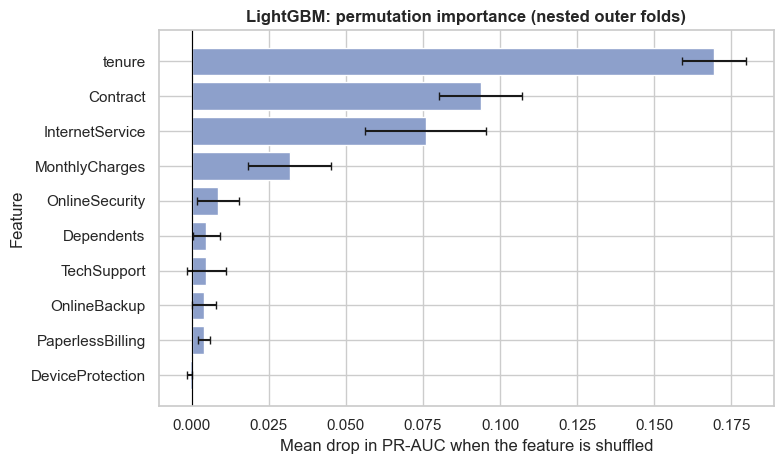

,mean,std
feature,,
tenure,0.1693,0.0105
Contract,0.0937,0.0135
InternetService,0.0759,0.0197
MonthlyCharges,0.0318,0.0135
OnlineSecurity,0.0085,0.0068
Dependents,0.0048,0.0045
TechSupport,0.0047,0.0063
OnlineBackup,0.0040,0.0039
PaperlessBilling,0.0040,0.0019


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.8))
perm_summary = plot_permutation_importance(ax, nested["importance"],
                                           f"{MODEL_NAME}: permutation importance (nested outer folds)")
plt.tight_layout()
save_figure(fig, f"{SLUG}_permutation_importance")
plt.show()
display(perm_summary.sort_values("mean", ascending=False).round(4))

**Interpretation.**
- `tenure` (0.169), `Contract` (0.094), `InternetService` (0.076) and `MonthlyCharges` (0.032) dominate, as for the other boosting models. `DeviceProtection` contributes nothing.

## 11. Strengths, Weaknesses and Conclusion

**Strengths**
- Ranking equal to Logistic Regression.
- Good calibration.
- Fast.

**Weaknesses**
- No meaningful gain.
- Opaque.
- An extra dependency.
- Leaf-wise growth needs strong constraints on small data.

**Conclusion:** three different boosting implementations (HistGradientBoosting, XGBoost, LightGBM) all land at PR-AUC 0.657–0.666. The ceiling comes from the information in the ten features, not from the choice of algorithm. Notebook 07 examines class imbalance, and notebook 08 makes the selection.

### Saving the training-stage results

The nested OOF predictions, fold metrics, permutation importances and the final (training-set) pipeline are stored in `reports/cv_results/` for the comparison in notebook 08.

In [10]:
payload = {
    "name": MODEL_NAME, "slug": SLUG, "oof": nested["oof"], "folds": nested["folds"], "params": nested["params"],
    "importance": nested["importance"], "seconds": nested["seconds"], "baseline": baseline,
    "final_params": final_params, "final_search_score": search.best_score_,
    "final_train_score": search.cv_results_["mean_train_score"][search.best_index_],
    "final_pipeline": search.best_estimator_, "grid": PARAM_GRID, "prep_config": FINAL_PREP_CONFIG,
    "y_index": y_train.index.to_numpy(), "interpretability_rank": INTERPRETABILITY_RANK,
}
print("Saved:", save_results(SLUG, payload).relative_to(PROJECT_ROOT))

Saved: reports\cv_results\06_lightgbm.joblib
